# IMDB SENTIMENT ANALYZER

## Overview
This notebook builds a binary **sentiment-classifier** for movie reviews on IMBD. Given the text of a review, the model predicts whether the reviewer`s opinion is **positive** or **negative** (hence the binary nature of the classifier). The project is a classic text-classification task, tackled with a classical machine learning approach based on [scikit-learn](https://scikit-learn.org/) rather than deep learning.

The goal is to build a fast, reproducible and interpretable pipeline, to understand **why** the model makes it predictions.

## Dataset
The data comes from the [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) on Kaggle, downloaded with `kagglehub`. The structure of the dataset is as follows:
- **50,000** movie reviews in **English**
- Two columns: `review` (the raw text of the review) | `sentiment` (`positive` or `negative`)
- Balanced classes: 25,000 positive and 25,000 negative reviews

## Approach
1. **Data loading and cleaning**: remove HTML tags and duplicate reviews
2. **Exploratory analysis**: class balance, review length, most frequent words
3. **Baseline**: bag-of-words (`CountVectorizer`) with a Multinominal Naive Bayes Classifier
4. **Main model**: TF-IDF features (unigrams and diagrams) with Logistic Regression, wrapped in a `scikit-learn` pipeline
5. **Hyperparameter tuning**: `GridSearchCV` with cross-validation on the training set only
6. **Evaluation**: accuracy, F1-score and confusion matrix on a held-out test set
7. **Interpretation**: the words with the strongest positive and negative weights

## Setup 
Install the dependencies listed in `requirements.txt`:

```bash
pip install -r requirements.txt
```

## Data Loading
As mentioned above we will use `kagglehub` to download the dataset from **Kaggle**, `pandas` will then be used to read the CSV file.

In [1]:
# Import dataset
import os
import pandas as pd
import kagglehub

# Download latest version (cached after the first run)
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews", force_download=True)
print(f"Path to dataset files: {path}") # verify dataset path
print(os.listdir(path)) # verify dataset file name

df = pd.read_csv(os.path.join(path, "IMDB Dataset.csv"))
df.head(10) # visualize the first 10 records of the dataset

100%|██████████| 25.7M/25.7M [00:01<00:00, 14.2MB/s]

Extracting files...


Path to dataset files: /home/ricca/.cache/kagglehub/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1
['IMDB Dataset.csv']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


## Data Cleaning and Exploratory Data Analysis
Before building any model, we need to take a first look at the data: its size, structure, missing values, duplicates, class balance and the length of the reviews. This is crucial in order to determine which cleaning steps are required and which metrics should be taken into account to evaluate the model.

### Structure of the dataset
We need to check the number of rows and columns, the column types and although we have already taken a look at the first 10 records in the cell above, let's print the first 5 records again.

In [2]:
print(f"Shape: {df.shape}")
df.info()
df.head()

Shape: (50000, 2)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### Missing values and duplicates
Missing values would need to be handled before vectorizing the text. Duplicates should also be handled, otherwise the same text could end up in both the training split and the testing split, inflating the evaluation metrics.

In [3]:
print(f"Missing values per column:\n{df.isna().sum()}\n")
print(f"Duplicated rows: {df.duplicated().sum()}")
print(f"Duplicated reviews: {df['review'].duplicated().sum()}")

Missing values per column:
review       0
sentiment    0
dtype: int64

Duplicated rows: 418
Duplicated reviews: 418


### Class balance
For a classification task it is important to know whether the classes are balanced. If they are, accuracy is a reliable metric, otherwise we would need to rely on different metrics (such as F1-score). 

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


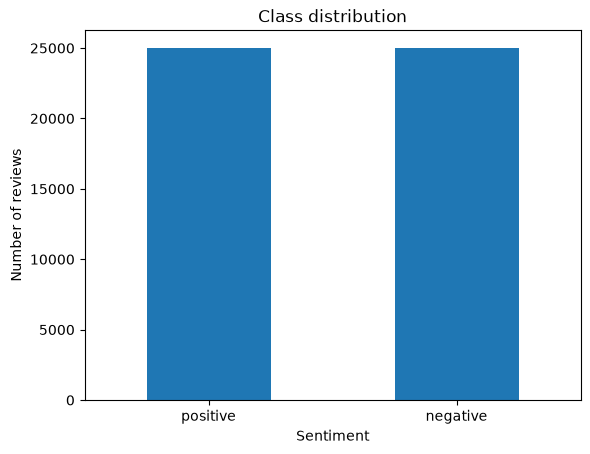

In [4]:
import matplotlib.pyplot as plt

counts = df['sentiment'].value_counts()
print(counts)

counts.plot(kind='bar')
plt.title("Class distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0) # for now rotation is set to 0 because we are only going to visualize 2 bars, therefore labels should not be overlaid
plt.show()

### Review length
The number of words in each review gives us an idea of how much text the model has to work with, and helps to spot unusually short or long reviews.

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_words, dtype: float64
                                              review sentiment  n_words
0  One of the other reviewers has mentioned that ...  positive      307
1  A wonderful little production. <br /><br />The...  positive      162
2  I thought this was a wonderful way to spend ti...  positive      166
3  Basically there's a family where a little boy ...  negative      138
4  Petter Mattei's "Love in the Time of Money" is...  positive      230


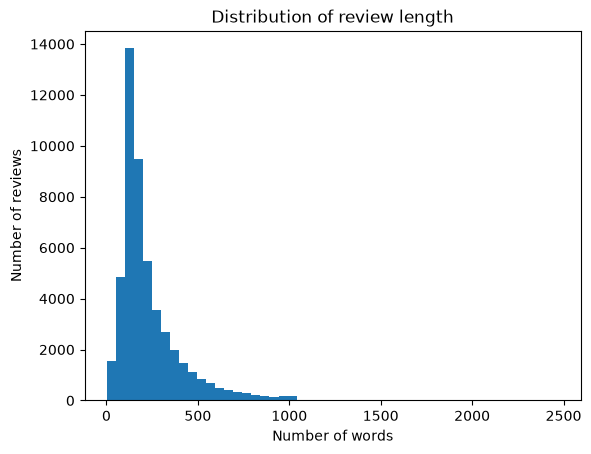

In [5]:
df["n_words"] = df["review"].str.split() # adds a new column to the dataset
df["n_words"] = df["n_words"].str.len()
print(df["n_words"].describe()) # prints information about the nature of the column "n_words"

print(df.head()) # let's visualize the first 5 records of the dataset again to see the addition of "n_words"

df["n_words"].plot(kind='hist', bins=50)
plt.title("Distribution of review length")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.show()

### Raw text inspection
We read a few random reviews and check for leftover HTML markup, which is noise that should be removed during cleaning.

In [6]:
# Fixed random_state for reproducibility
for text in df["review"].sample(n=3, random_state=42):
    print(text[:500], "\n---")

n_html = df["review"].str.contains("<br />", regex=False).sum()
print(f"Reviews containing '<br />': {n_html}")

I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Di 
---
Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as you can think of that just adore this T.V miniseries. It has elements that can be found in almost every other show on T.V, character driven drama that could be from an Australian soap opera; yet in the same episode it has science fact & fiction that would give even the hardiest "Trekkie" a run for h

### Observations
- The dataset contains **50,000 entries (reviews)** and **2 columns** with no missing values.
- Classes are **balanced** (25000 positive, 25000 negative), therefore **accuracy/F1-score** is an appropriate metric.
- There are **418** duplicated reviews, which will be removed before splitting the data.
- Reviews have a median length of **~231 words**, with a long tail up to **2,470 words**.
- **29,200 entries (reviews)** contain HTML tags such as `<br />`, which will be removed in the cleaning step.

## Data Cleaning
Based on the exploratory data analysis, we apply these necessary cleaning steps before moving on to the training phase:

1. **Remove duplicated reviews**, so that the same text cannot end up both in the training and the test set.
2. **Remove HTML tags**, which carry no sentiment information and would only introduce noise to the vocabulary.
3. **Encode the labels** as integers (positive = 1, negative = 0), since `scikit-learn` models expect numeric targets.

It is wise to work on a copy of the original DataFrame, so that the raw data remains available for comparison.

In [7]:
# Create a duplicate of the original DataFrame
df_clean = df.copy()

n_before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="review").reset_index(drop=True)
print(f"Removed {n_before - len(df_clean)} duplicated reviews, {len(df_clean)} left")

# Replace any HTML tag with a space so that words separated by <br /> do not get glued together
df_clean["review"] = df_clean["review"].str.replace(r"<[^>]+>", " ", regex=True)

# Collapse the multiple spaces left behind
df_clean["review"] = df_clean["review"].str.replace(r"\s+", " ", regex=True).str.strip()

# Verify that no tag is left
print(f"Reviews still containing tags: {df_clean['review'].str.contains(r'<[^>]+>', regex=True).sum()}")

# Encode labels
df_clean["label"] = (df_clean['sentiment'] == "positive").astype(int)

print(df_clean["label"].value_counts())
df_clean[["review", 'sentiment', "label"]].head()

Removed 418 duplicated reviews, 49582 left
Reviews still containing tags: 0
label
1    24884
0    24698
Name: count, dtype: int64


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. The filming tec...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


### Cleaning summary
- Duplicated reviews were removed, leaving **495,82 reviews**.
- HTML tags were replaced with spaces, and repeated whitespace was collapsed.
- Labels were encoded as `1` (positive) and `0` (negative) in a new `label` column.
- Class balance after cleaning **24,884 positive / 24,689 negative**.

## Train/Test Split

We split the data into a **training set (80%)** and a **test/validation set (20%)**:

- The training set is used to fit the models and to tune hyperparameters (through cross-validation).
- The test set is kept untouched until the final evaluation, so that the reported metrics estimate how the model behaves on unseen reviews.

Two details matter here:

- `stratify=y` keeps the same proportion of positive and negative reviews in both sets.
- `random_state` is fixed for reproducibility.

The split is done **before** any text vectorization. Fitting a vectorizer on the full dataset would leak information about the test set (vocabulary and IDF weights) into the training process and inflate the evaluation metrics.

In [8]:
from sklearn.model_selection import train_test_split

X = df_clean["review"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print(f"Train: {X_train.shape[0]} reviews")
print(f"Test: {X_test.shape[0]} reviews")
print(f"\nPositive share in train: {y_train.mean():.3f}")
print(f"Positive share in test: {y_test.mean():.3f}")

Train: 39665 reviews
Test: 9917 reviews

Positive share in train: 0.502
Positive share in test: 0.502


The two sets contain **39,665** (train) and **9,917** (test) reviews and preserve the class proportions (about **50.2%** positive in both). The share is slightly above 50% because the duplicates removed during cleaning were more frequent among negative reviews.

## Baseline Model

Before building a more refined model, we need a **baseline**, a simple model that gives us a reference score. Any later improvement will be measured against it.

The baseline combines:

- **`CountVectorizer`**, a bag-of-words representation: each review becomes a vector of word counts, ignoring word order.
- **Multinomial Naive Bayes**, a fast probabilistic classifier that works well with word counts.

Both steps are wrapped in scikit-learn `Pipeline`. This way, during cross-validation the vectorizer is fitted only on the training folds, and the vocabulary of the validation fold never leaks into the model.

We evaluate the baseline with **5-fold cross-validation on the training set**. The test set stays untouched until the final evaluation.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

baseline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(),)
])

scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="accuracy")

print(f"Accuracy per fold: {scores.round(4)}")
print(f"Mean accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Accuracy per fold: [0.846  0.8477 0.8438 0.847  0.8436]
Mean accuracy: 0.8456 (+/- 0.0017)


The baseline reaches a mean cross-validation accuracy of **0.8456** (std **0.0017**). The low standard deviation shows that the score is stable across folds. This is the score that the next models need to beat.

## Main Model: TF-IDF + Logistic Regression

The baseline treats every word count as equally informative. We improve on it with two changes:

- **TF-IDF** weighting (`TfidfVectorizer`) instead of raw counts: words that appear in many reviews ("movie", "film") get a lower weight, while words that are distinctive of a few reviews get a higher one.
- **Unigrams and bigrams** (`ngram_range=(1, 2)`): bigrams like "not good" or "waste of" capture short negations and expressions that single words cannot.

As a classifier we use **Logistic Regression**, a linear model that works well on high-dimensional sparse text data and is easy to interpret (each word gets a coefficient).

To keep the vocabulary manageable, `min_df=5` discards n-grams that appear in fewer than 5 reviews: they are too rare to generalize and mostly add noise.

As before, everything is wrapped in a `Pipeline` and evaluated with 5-fold cross-validation on the training set.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf_lr = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), min_df=5)),
    ("classifier", LogisticRegression(max_iter=1000)),
])

scores_lr = cross_val_score(tfidf_lr, X_train, y_train, cv=5, scoring="accuracy")

print(f"Accuracy per fold: {scores_lr.round(4)}")
print(f"Mean accuracy: {scores_lr.mean():.4f} (+/- {scores_lr.std():.4f})")

Accuracy per fold: [0.9032 0.9019 0.8987 0.8974 0.8992]
Mean accuracy: 0.9001 (+/- 0.0022)


The TF-IDF + Logistic Regression pipeline reaches a mean cross-validation accuracy of **0.9001** (std **0.0022**), compared with **0.8456** for the baseline: an improvement of about **5.5 percentage points**. The gain comes from the richer text representation (TF-IDF weighting and bigrams) and from a classifier that, unlike Naive Bayes, learns how much each feature contributes to the decision.

## Hyperparameter Tuning

So far we used default values for most hyperparameters. Now we will focus on searching for a better configuration with `GridSearchCV`, which tries every combination in a grid and scores each one with cross-validation on the training set.

We tune:

- `ngram_range`: whether to use only single words `(1, 1)` or also pairs `(1, 2)`.
- `C`: the inverse of the regularization strength of Logistic Regression. Small values apply strong regularization (simpler model, less overfitting), while large values let the model fit the training data more closely.

The search runs on the training set only. The test set is still untouched.

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [1, 3, 10, 30],
}

grid = GridSearchCV(
    tfidf_lr,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=1,
    verbose=1,
)
grid.fit(X_train, y_train)

print(f"Bast parameters: {grid.best_params_}")
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Bast parameters: {'classifier__C': 30, 'vectorizer__ngram_range': (1, 2)}
Best CV accuracy: 0.9105


In [12]:
import pandas as pd

results = pd.DataFrame(grid.cv_results_)
results[["param_vectorizer__ngram_range", "param_classifier__C", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False)

,param_vectorizer__ngram_range,param_classifier__C,mean_test_score,std_test_score
7,"(1, 2)",30,0.910500,0.001985
5,"(1, 2)",10,0.910425,0.001662
3,"(1, 2)",3,0.907979,0.001624
1,"(1, 2)",1,0.900063,0.002155
2,"(1, 1)",3,0.897971,0.002027
4,"(1, 1)",10,0.895298,0.002872
0,"(1, 1)",1,0.892676,0.002507
6,"(1, 1)",30,0.888945,0.003204


### Refining the search

The first search selected `ngram_range=(1, 2)` and `C=30`, which is the **upper edge** of the grid we tried. When the best value sits on the edge, the true optimum may lie beyond it, so we run a second search that extends the range of `C` while keeping the n-gram range fixed.

In [13]:
from sklearn.model_selection import GridSearchCV

param_grid_2 = {
    "vectorizer__ngram_range": [(1, 2)],
    "classifier__C": [30, 100, 300],
}

grid_2 = GridSearchCV(
    tfidf_lr,
    param_grid_2,
    cv=5,
    scoring="accuracy",
    n_jobs=1,
    verbose=1,
)
grid_2.fit(X_train, y_train)

print(f"Bast parameters: {grid_2.best_params_}")
print(f"Best CV accuracy: {grid_2.best_score_:.4f}")

pd.DataFrame(grid_2.cv_results_)[["param_vectorizer__ngram_range", "param_classifier__C", "mean_test_score", "std_test_score"]]

Fitting 5 folds for each of 3 candidates, totalling 15 fits


Bast parameters: {'classifier__C': 30, 'vectorizer__ngram_range': (1, 2)}
Best CV accuracy: 0.9105


,param_vectorizer__ngram_range,param_classifier__C,mean_test_score,std_test_score
0,"(1, 2)",30,0.910500,0.001985
1,"(1, 2)",100,0.910450,0.001836
2,"(1, 2)",300,0.910047,0.002222


The refined search confirmed `C=30` as the best value: both lower (`C=10`, first search) and higher values (`C=100`, `C=300`) perform worse, so the optimum is now bracketed. The tuned model reaches a cross-validation accuracy of **0.9105**, compared with **0.9001** for the default settings and **0.8456** for the baseline.

## Final Evaluation on the Test Set

We now evaluate the tuned model on the **test set**, which has not been used so far: not for fitting, not for tuning, not for model selection. This is the only time we look at it, so the resulting metrics are an honest estimate of how the model performs on unseen reviews.

`GridSearchCV` has already refitted the best pipeline on the **whole training set** (`refit=True` by default), so we can use `best_estimator_` directly.

We report:

- **Accuracy**: the fraction of reviews classified correctly.
- **Precision, recall and F1-score** for each class.
- **Confusion matrix**: which kinds of errors the model makes.

Test accuracy: 0.9142

              precision    recall  f1-score   support

    negative       0.92      0.91      0.91      4940
    positive       0.91      0.92      0.92      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



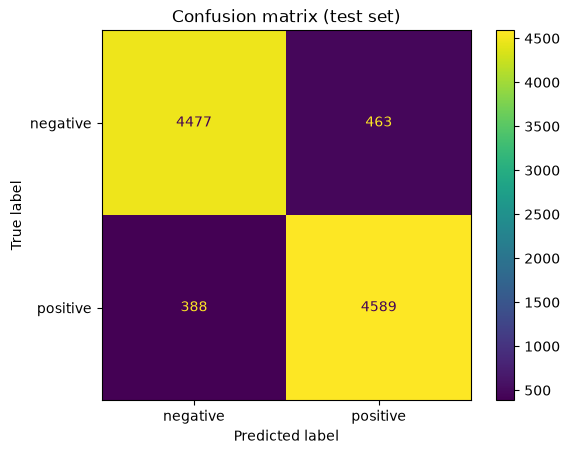

In [14]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

best_model = grid_2.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["negative", "positive"]
)

plt.title("Confusion matrix (test set)")
plt.show()

On the test set, the model reaches an accuracy of **0.9142**, in line with the cross-validation estimate (**0.9105**). Precision, recall and F1-score are balanced across the two classes (F1 of **0.91** for negative and **0.92** for positive reviews), so the model does not favor one sentiment over the other. The confusion matrix shows **...** false positives (negative reviews predicted as positive) and **...** false negatives (positive reviews predicted as negative).

## Model Interpretation

A linear model is easy to inspect: after training, each feature (here, each word or word pair) has a **coefficient** that tells how much it pushes the prediction towards the positive class (positive coefficient) or the negative class (negative coefficient).

We extract the features with the largest coefficients in each direction to check that the model has learned sensible patterns rather than noise.

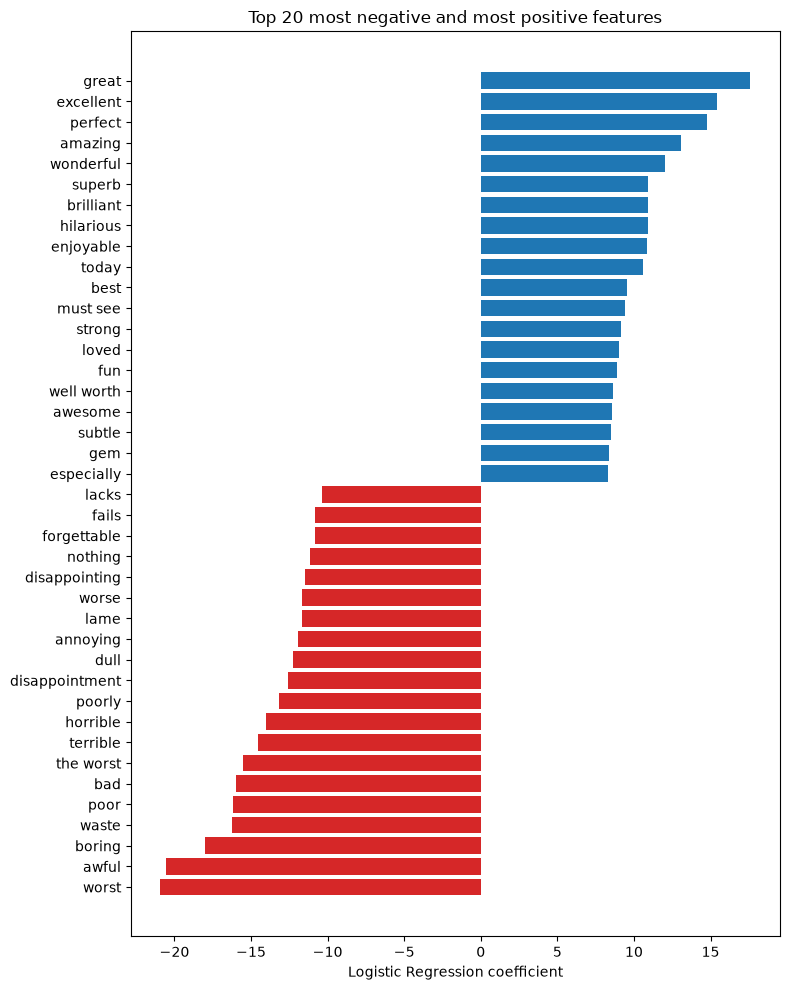

In [16]:
import numpy as np

vectorizer = best_model.named_steps["vectorizer"]
classifier = best_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefs = classifier.coef_[0]

top_n = 20
order = np.argsort(coefs)
top_idx = np.concatenate([order[:top_n], order[-top_n:]])

coef_df = pd.DataFrame({
    "feature": feature_names[top_idx],
    "coefficient": coefs[top_idx],
})

colors = ["tab:red" if c < 0 else "tab:blue" for c in coef_df["coefficient"]]

plt.figure(figsize=(8, 10))
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.title(f"Top {top_n} most negative and most positive features")
plt.xlabel("Logistic Regression coefficient")
plt.tight_layout()
plt.show()

The most negative features include **worst, awful, boring, waste, poor, bad** and the bigram **the worst**, while the most positive ones include **great, excellent, perfect, amazing, wonderful, superb** and the bigrams **must see** and **well worth**. The model relies mostly on strongly polarized words, which matches intuition.

A few features are less obvious. **"today"** carries a large positive weight even though it is not a sentiment word. A quick check confirms that it is a genuine statistical signal in this dataset: **73.7%** of the 2,127 reviews containing it are positive, against about 50% overall. Phrases such as "still holds up today" are likely more common in positive reviews. This shows that a linear bag-of-words model captures correlations present in the data, not only the meaning of the words.

In [18]:
mask = df_clean["review"].str.contains(r"\btoday\b", case=False, regex=True)
print(f"Reviews containing 'today': {mask.sum()}")
print(f"Positive share among them: {df_clean.loc[mask, 'label'].mean():.3f}")

Reviews containing 'today': 2127
Positive share among them: 0.737


## Trying the Model on Custom Sentences

As a last check, we use the trained pipeline on a few sentences written by hand. For each text, `predict_proba` returns the estimated probability that the sentiment is positive. The sentences are chosen to cover easy cases as well as situations that are known to be hard for a bag-of-words model: negation, mixed opinions and sarcasm.

In [19]:
examples = {
    "clear positive":  "This movie was absolutely fantastic, I loved every minute of it.",
    "clear negative":  "A complete waste of time. Boring plot and terrible acting.",
    "negation":        "Not good at all.",
    "negated negative": "It was not bad, actually quite enjoyable.",
    "reversed expectation": "I expected it to be bad, but it was surprisingly good.",
    "mixed":           "The acting was great, but the story was boring and the ending was a disappointment.",
    "sarcasm":         "Oh great, another two hours of my life I will never get back.",
    "neutral":         "The film is about a man who travels to another city.",
}

texts = list(examples.values())
probs = best_model.predict_proba(texts)[:, 1]

for (kind, text), p in zip(examples.items(), probs):
    label = "positive" if p >= 0.5 else "negative"
    print(f"{p:.2f}  {label:<8}  [{kind}]  {text}")

0.98  positive  [clear positive]  This movie was absolutely fantastic, I loved every minute of it.
0.00  negative  [clear negative]  A complete waste of time. Boring plot and terrible acting.
0.00  negative  [negation]  Not good at all.
0.80  positive  [negated negative]  It was not bad, actually quite enjoyable.
0.96  positive  [reversed expectation]  I expected it to be bad, but it was surprisingly good.
0.00  negative  [mixed]  The acting was great, but the story was boring and the ending was a disappointment.
0.18  negative  [sarcasm]  Oh great, another two hours of my life I will never get back.
0.90  positive  [neutral]  The film is about a man who travels to another city.


In [20]:
def explain(text):
    x = vectorizer.transform([text]).tocoo()
    contrib = pd.Series(x.data * coefs[x.col], index=feature_names[x.col]).sort_values()
    logit = contrib.sum() + classifier.intercept_[0]
    print(f"Intercept: {classifier.intercept_[0]:+.2f}")
    print(contrib.round(2).to_string())
    print(f"\nSum (logit): {logit:+.2f}  ->  P(positive) = {1 / (1 + np.exp(-logit)):.2f}")

explain("The film is about a man who travels to another city.")

Intercept: -0.04
to another    -0.39
another       -0.30
to            -0.13
the film      -0.11
about         -0.03
who travels    0.02
the            0.05
man            0.11
man who        0.11
film           0.13
is             0.14
is about       0.25
who            0.28
film is        0.29
travels to     0.35
city           0.40
about man      0.42
travels        0.61

Sum (logit): +2.17  ->  P(positive) = 0.90


The model handles clear cases, simple negations ("Not good at all") and even the sarcastic sentence correctly, and it labels the mixed review as negative, which is defensible given that most cues are negative.

Its main weakness shows on the **neutral** sentence, which receives a confident positive score (**0.90**). Decomposing the prediction shows why: no single word dominates (the largest contribution is "travels", +0.61), but almost all of the 18 features have a small positive weight and nothing pushes in the opposite direction, so their sum reaches +2.17 in log-odds. In addition, the same word is counted several times through unigrams and bigrams ("travels", "who travels", "travels to"). The model was trained only on strongly opinionated reviews: it has no notion of "neutral" and must always pick a side, and probabilities from a weakly regularized logistic regression tend to be overconfident.

The decomposition also helps explain the sarcastic example: the word "another" has a negative weight (-0.30), which probably offsets "great". The model does not understand sarcasm; it gets the right answer partly through unrelated words.

Being a bag-of-words model, it ignores word order and sentence structure, so it cannot truly understand negation, contrast ("but") or sarcasm.

## Conclusions

### Results

| Model | CV accuracy (train) | Test accuracy |
|---|---|---|
| Baseline: CountVectorizer + Multinomial Naive Bayes | 0.8456 | not evaluated |
| TF-IDF (1-2 grams) + Logistic Regression, default settings | 0.9001 | not evaluated |
| TF-IDF (1-2 grams) + Logistic Regression, tuned (`C=30`) | 0.9105 | **0.9142** |

The test set was used only once, on the final model, so the test accuracy is an unbiased estimate of the performance on unseen reviews. It is consistent with the cross-validation score, which suggests that the model is not overfitting the training data or the tuning procedure.

Most of the improvement over the baseline (about +5.5 points) comes from the richer representation (TF-IDF weighting and bigrams) and from the discriminative classifier; hyperparameter tuning added roughly one more point.

### What the model learned

The largest coefficients correspond to strongly polarized words (*worst, awful, boring, waste* vs. *great, excellent, perfect, amazing*) and a few bigrams (*the worst, must see, well worth*), which confirms that the model learned sensible patterns. It also picked up dataset-specific correlations, such as the word *today*, which appears in 73.7% of positive reviews that contain it.

### Limitations

- **Bag-of-words representation**: word order and sentence structure are ignored, so negation, contrast and sarcasm are handled only through the individual words and bigrams involved.
- **No neutral class**: the model was trained only on clearly positive or negative reviews, so a neutral sentence still receives a confident score (0.90 in our example).
- **Overconfident probabilities**: with weak regularization (`C=30`), `predict_proba` tends to return extreme values, even on uncertain inputs.
- **Domain and language**: the model has been trained on English movie reviews and should not be expected to transfer to other domains (e.g. product reviews or tweets) or languages.
- **Spurious correlations**: features such as *today* show that the model can rely on patterns that are not related to sentiment.

### Possible improvements

- Compare other linear models (e.g. `LinearSVC`, `SGDClassifier`) and a wider hyperparameter search (e.g. `min_df`, `max_features`, trigrams).
- Evaluate stop-word removal and other preprocessing choices.
- Calibrate the predicted probabilities (`CalibratedClassifierCV`).
- Fine-tune a pre-trained transformer (e.g. DistilBERT), which typically reaches higher accuracy and handles negation and context better, at a much higher computational cost.

In [ ]:
from pathlib import Path
import joblib

model_path = Path("..") / "model" / "imdb_sentiment_analyzer.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

Model saved to model/imdb_sentiment_analyzer.joblib (7.5 MB)
